# MonReader — 03 Model and Color Representation Comparison

> **Submission status:** reproducible historical comparison notebook.  
> **Scientific authority:** historical pre-V2 evidence; current V2 remains authoritative.

## Purpose

Compare the frozen tuned Scratch CNN with the historical ImageNet-pretrained ResNet18 on matched O/S/T/ST populations, then close the historical RGB/grayscale branch using its predefined evidence gate.

## Notebook flow

**Frozen model-family comparison → matched confusion matrices → grayscale ablation → bounded interpretation**

No training or new model selection is performed in report mode.

---

In [ ]:
from pathlib import Path
import sys

# Portable repository discovery: no machine-specific path assumptions.
HERE = Path.cwd().resolve()
REPO_ROOT = next(
    (p for p in [HERE, *HERE.parents] if (p / "submission" / "results").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Run this notebook from inside a clone of the MonReader repository "
        "or set MONREADER_REPO_ROOT."
    )

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from submission.src.repro import (
    load_local_env,
    load_snapshot,
    display_snapshot,
    display_figure,
    figures_dir,
    data_root,
)

load_local_env()

print(f"Repository root: {REPO_ROOT}")
print(f"Committed results: {REPO_ROOT / 'submission' / 'results'}")
print(f"Committed figures: {figures_dir()}")
print(
    "Optional local data root:",
    data_root() or "not configured — report mode remains fully reviewable",
)


## Scratch CNN versus ResNet18

| regime   |   scratch_macro_f1 |   resnet18_macro_f1 |   delta_macro_f1 |   scratch_notflip_f1 |   resnet18_notflip_f1 |   scratch_flip_f1 |   resnet18_flip_f1 |   scratch_mcc |   resnet18_mcc |
|:---------|-------------------:|--------------------:|-----------------:|---------------------:|----------------------:|------------------:|-------------------:|--------------:|---------------:|
| O        |             0.9899 |              0.995  |           0.005  |               0.9902 |                0.9951 |            0.9897 |             0.9948 |        0.9799 |         0.99   |
| S        |             0.44   |              0.9584 |           0.5184 |               0.7347 |                0.9635 |            0.1453 |             0.9533 |        0.2133 |         0.9168 |
| T        |             0.8305 |              0.9091 |           0.0786 |               0.8271 |                0.9194 |            0.8339 |             0.8989 |        0.6641 |         0.8334 |
| ST       |             0.7906 |              0.8772 |           0.0867 |               0.8148 |                0.9067 |            0.7664 |             0.8478 |        0.5813 |         0.7812 |

> Snapshot source: `submission/results/resnet18_vs_scratch_detailed.csv`


### Interpretation

ResNet18 was very similar to the scratch model under O, but substantially more robust under the historical stress regimes. The largest historical difference was under S (Macro-F1 delta ≈ **+0.518**).

This is a matched historical reference comparison, not permission to retroactively retune or replace a model based on test behaviour.

## Frozen ResNet18 confusion matrices

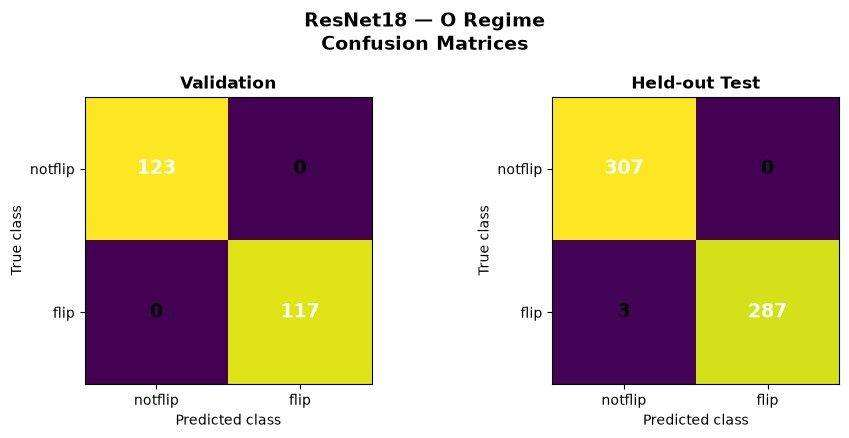

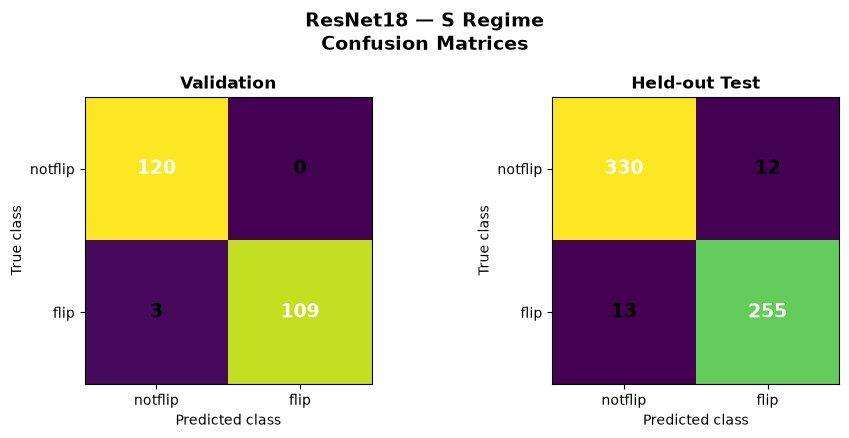

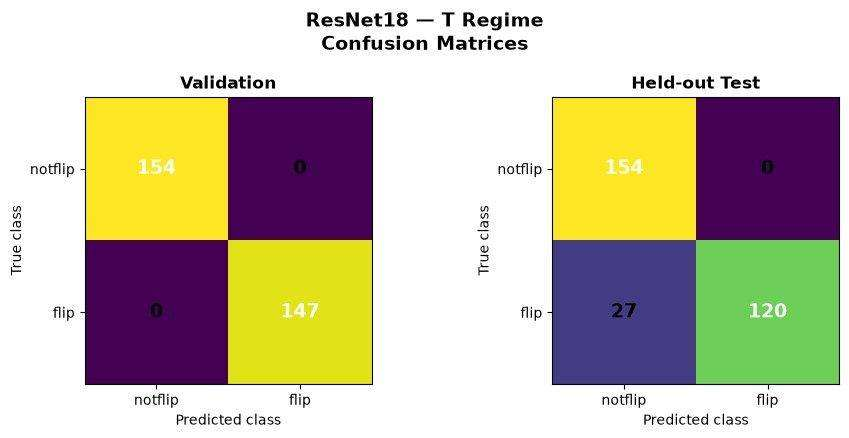

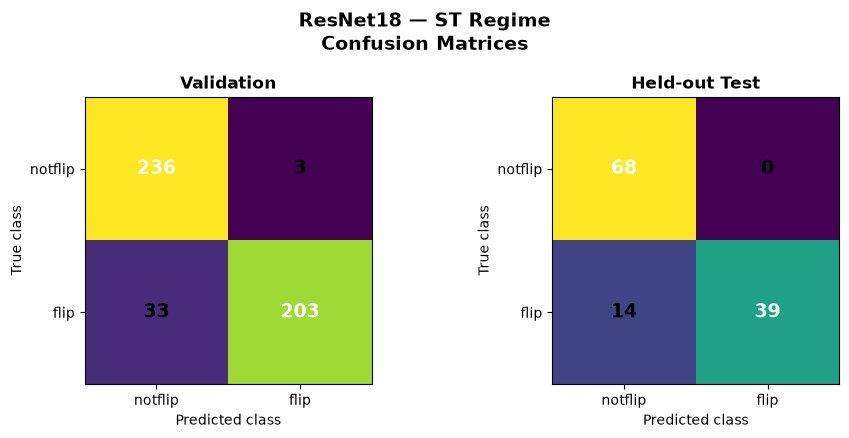

## Held-out model comparison

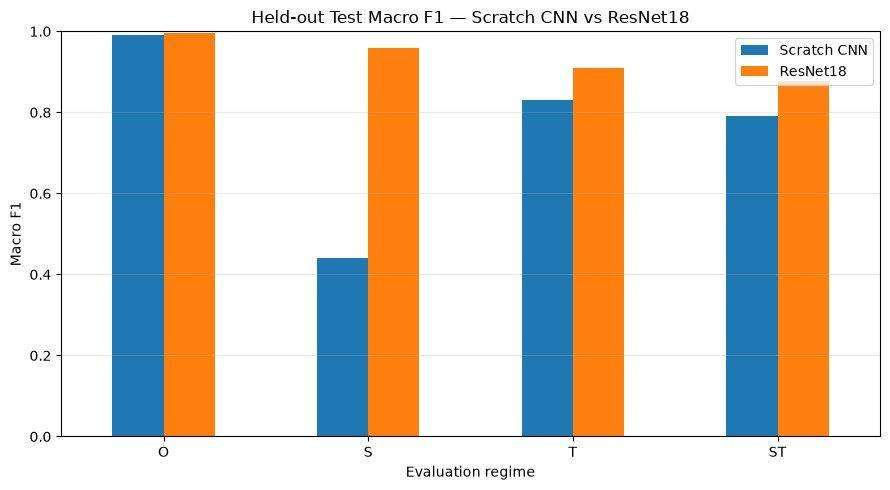


## Historical grayscale ablation

| regime   |   rgb_macro_f1 |   grayscale_macro_f1 |   delta_macro_f1_gray_minus_rgb |   ci_lower |   ci_upper | meaningful_color_effect_supported   |
|:---------|---------------:|---------------------:|--------------------------------:|-----------:|-----------:|:------------------------------------|
| O        |         0.9899 |               0.9966 |                          0.0067 |    -0.0017 |     0.0168 | False                               |
| ST       |         0.7906 |               0.6901 |                         -0.1005 |    -0.2591 |     0.0353 | False                               |

> Snapshot sources: `submission/results/final_color_ablation_summary.csv` and `submission/results/grayscale_bootstrap_summary.csv`


The grayscale experiment did **not** satisfy the full predefined meaningful-color-effect gate. It therefore remains closed historical secondary evidence and does not justify additional model redesign.

## Notebook conclusion

The historical analysis supported using ResNet18 as the primary model for the subsequent robustness/stress-analysis notebook, while retaining the Scratch CNN as a reference comparator. Notebook 4 then quantifies uncertainty and failure behaviour without reopening model selection.